In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx

from hcnn.environment import Environment
from hcnn.optimization import OptimizationSolverOSQP
from hcnn.policy.policy_mlp import PolicyMLP
from hcnn.projection import ProjectionNoSubstitutionNoTerminal
from hcnn.system_constraints import SystemConstraintsSphere
from hcnn.system_dynamics import SystemDynamicsLinear

center = jnp.array([1.0, 1.0])
radius = 3.0

state_matrix = jnp.array([[1.0, -1.0], [1.0, 0.0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
sys_dynamics = SystemDynamicsLinear.factory(state_matrix, input_matrix)
sys_constraints = SystemConstraintsSphere.factory(center=center, radius=radius)
policy = PolicyMLP.factory(
    layer_sizes=[2, 3, 3, 3, 1],
    dropout_rate=0.2,
    rngs=nnx.Rngs(42),
)
projection = ProjectionNoSubstitutionNoTerminal.factory(
    sys_dynamics,
    sys_constraints,
    policy,
    horizon=10,
    relaxation_penalty=6.0,
)
solver = OptimizationSolverOSQP()
environment = Environment(policy, projection, solver)

In [2]:
nnx.display(projection)

In [3]:
nnx.display(policy)

In [4]:
policy_params = nnx.state(policy, nnx.Param)
context = projection.Context(
    initial_state=center,
    policy_params=policy_params,
    jax_key=jax.random.key(42),
)
x_star = solver._solve(projection, context)
rollout = projection.get_rollout(x_star)

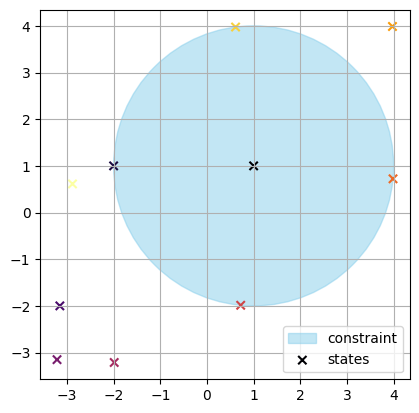

In [5]:
# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
order = jnp.arange(len(rollout.states))
plt.scatter(
    rollout.states[:, 0], rollout.states[:, 1], c=order, cmap="inferno", marker="x", label="states"
)
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()

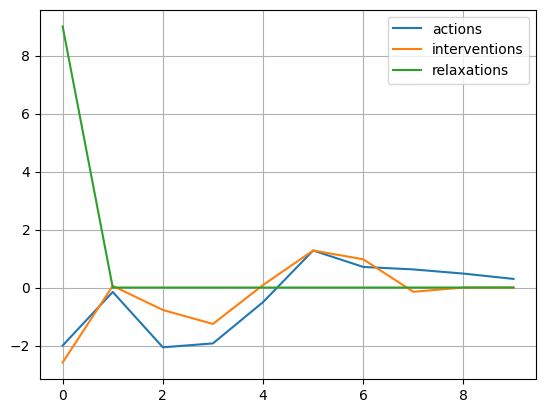

In [6]:
fig, ax = plt.subplots()
plt.plot(rollout.actions, label="actions")
plt.plot(rollout.interventions, label="interventions")
plt.plot(rollout.relaxations, label="relaxations")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
view_range = 6.0
samples_per_axis = 30
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(lambda state, jax_key: environment.step(state, jax_key=jax_key))(
    states,
    jax.random.split(jax.random.key(42), len(states)),
)

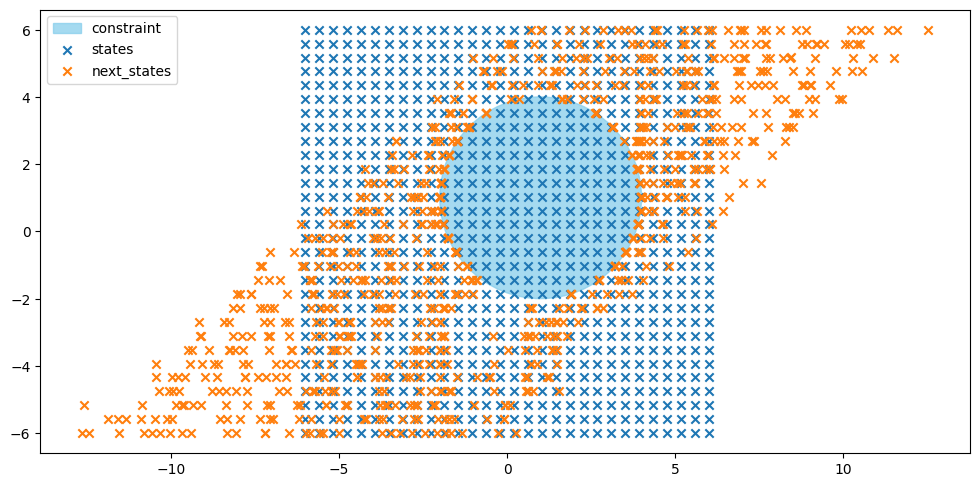

In [8]:
fig, ax = plt.subplots(figsize=(12, 12))
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.scatter(states[:, 0], states[:, 1], marker="x", label="states")
plt.scatter(next_states[:, 0], next_states[:, 1], marker="x", label="next_states")
plt.legend()
plt.show()